In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import roc_curve, auc,  roc_auc_score
from scipy.stats import randint,uniform

df=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv',index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')
df.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,4,1,2,0,2,0,0,0,0,0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,7,3,2,1,0,5,1,1,0,0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,7,3,1,1,0,5,1,0,0,0
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,4,1,1,1,2,1,1,0,0,0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,1,4,0,1,0,1,0,0,0,0


## 🛑 **Process to obtain the best model**

## 🛑 Task 1.4. PCA:  **Prediction of SFDM2**

---



### 🛑FEATURE SELECTION

1. Improves Model Accuracy: By removing irrelevant features, the model can focus on the most important data points, leading to better performance.

2. Reduces Overfitting: Too many features can prevent your model from learning noise in the data. Reducing the feature set can help mitigate overfitting.
Speeds up Training: Less data means faster computation. Feature selection can significantly reduce the training time, especially with large datasets.

3. Enhances Interpretability: With fewer features, it’s easier to understand how the model makes decisions

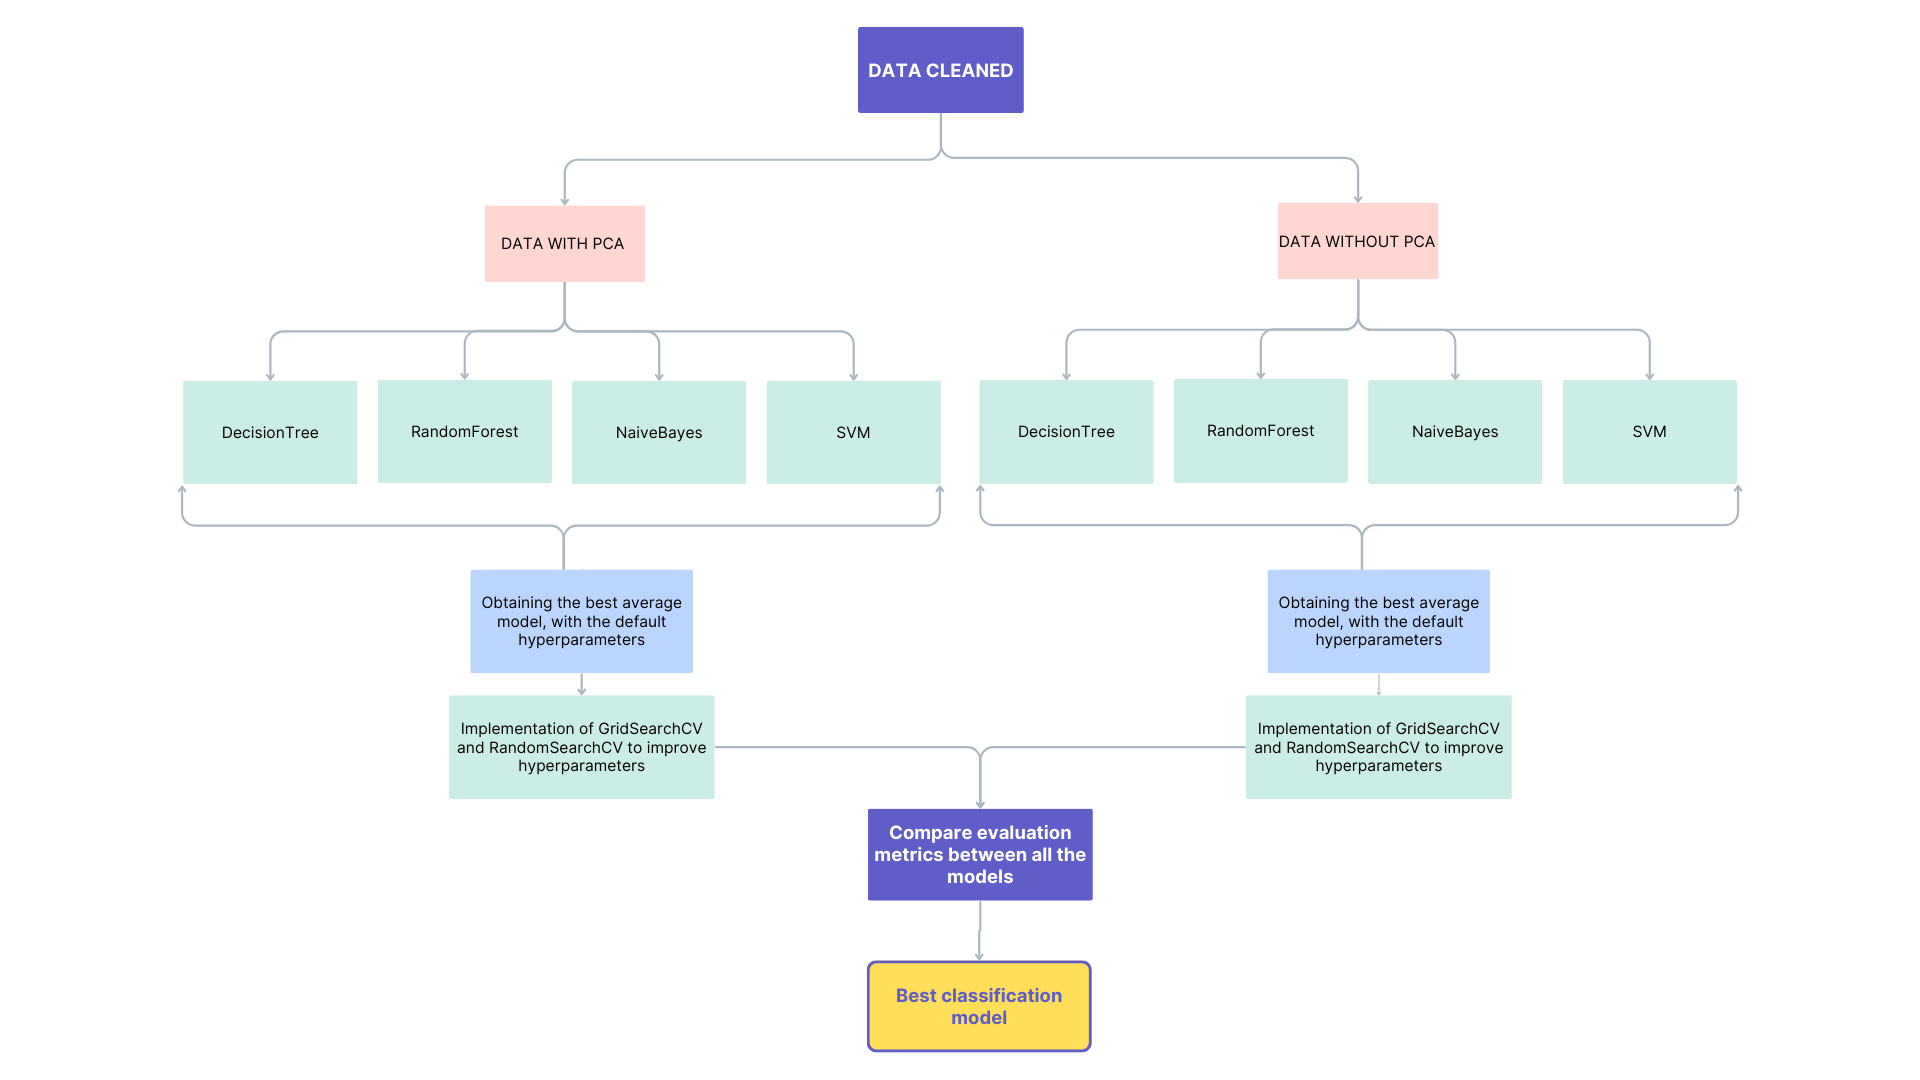

### 🛑 DATA SPLICING WE WILL USE STRATIFIED KFOLD

- First, we separate the data into the target variable and the features. It is crucial to identify and save the names of the qualitative columns, since principal component analysis (PCA) cannot be applied to them.

In [40]:
target=df['sfdm2']
features=df.drop(['sfdm2'],axis=1)
categorical_features_cols= categorical_features.drop(['sfdm2'],axis=1).columns

- We are using a 70/10/20 data split strategy, but this time, we will apply a stratified k-fold approach. Specifically, we will calculate 10 folds: 5 external folds and 2 internal folds for validation. 
    
    The external folds will determine the training and testing splits, while the internal folds will further divide the training data into training and validation sets. This ensures a robust evaluation process by maintaining the data distribution and minimizing potential biases.


Cumulative explained variance for each number of components: [0.13733267 0.22783311 0.30883794 0.37639607 0.43234604 0.48291319
 0.5303165  0.57625834 0.61899219 0.66089403 0.70120471 0.73985511
 0.77767819 0.8142917  0.84722134 0.87843365 0.90869615 0.93731966
 0.96315661 0.98666916 0.99608029 1.        ]


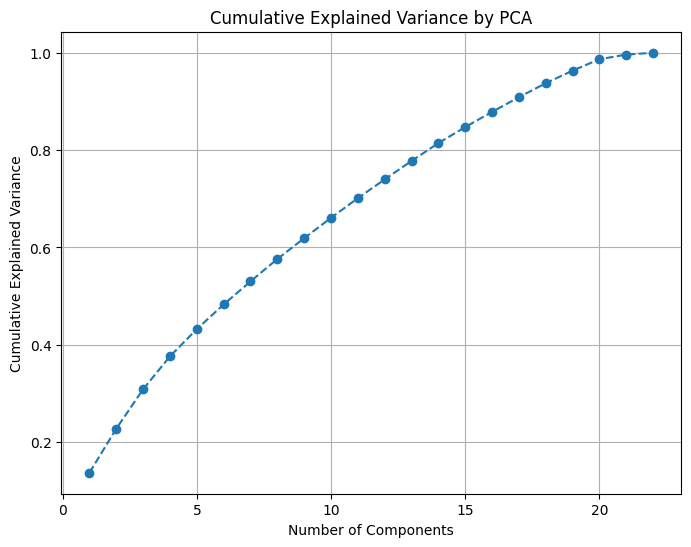

The optimal number of components to capture 85% of the variance is: 16


/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_4661/3471206869.py:111: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-d

Cumulative explained variance for each number of components: [0.13491753 0.22756737 0.30980973 0.38139634 0.43329423 0.48330459
 0.5310973  0.57634467 0.62018776 0.66282804 0.70260635 0.73980793
 0.77626394 0.8114539  0.8456455  0.87802301 0.90774029 0.93578522
 0.96176791 0.98601092 0.99586293 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


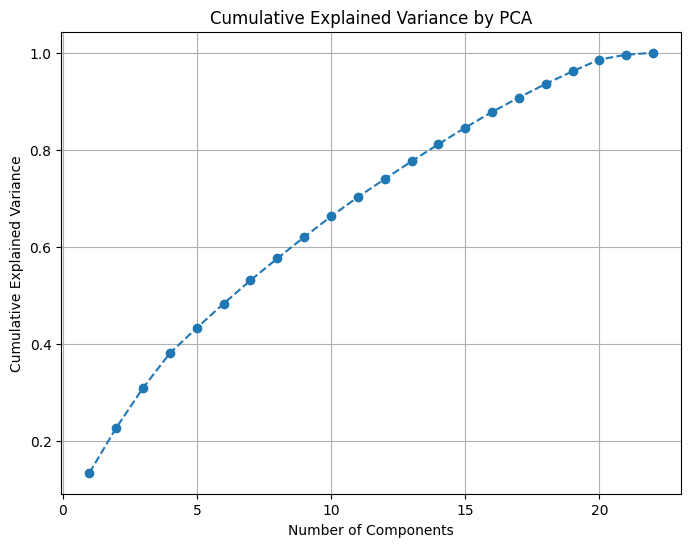

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.13829919 0.22918689 0.30991714 0.37900884 0.43327719 0.48630582
 0.53339404 0.57844942 0.62240006 0.66489229 0.70600794 0.74299002
 0.77945975 0.81484666 0.84893653 0.88199893 0.91091932 0.93925934
 0.96397754 0.98648662 0.99605165 1.        ]


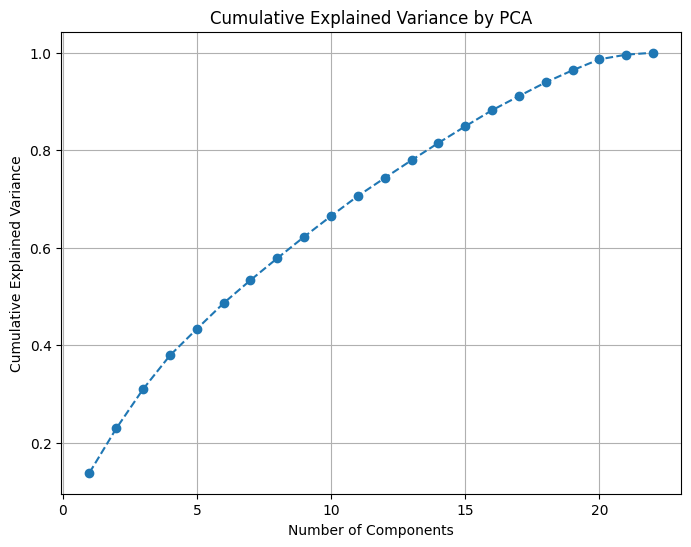

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.13339407 0.22520863 0.30671768 0.3755699  0.42875689 0.4786636
 0.52781847 0.5729955  0.61665887 0.65819365 0.6990664  0.7380904
 0.77547602 0.81072726 0.84462844 0.87736011 0.90786557 0.936864
 0.9630602  0.98670254 0.99573744 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


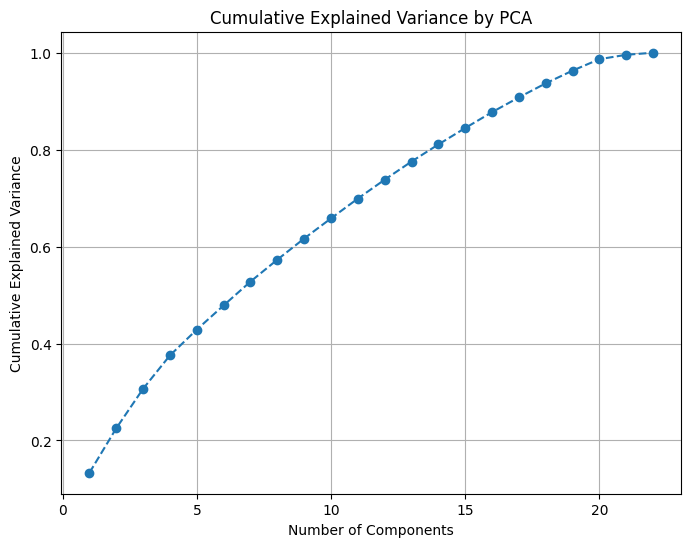

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

Cumulative explained variance for each number of components: [0.13829405 0.22919067 0.31203203 0.3800036  0.4317945  0.48343949
 0.53085116 0.57627036 0.62045502 0.66245941 0.70340309 0.74176363
 0.77958137 0.81444434 0.84780221 0.88048135 0.91095888 0.93988178
 0.96439254 0.98810666 0.99629134 1.        ]


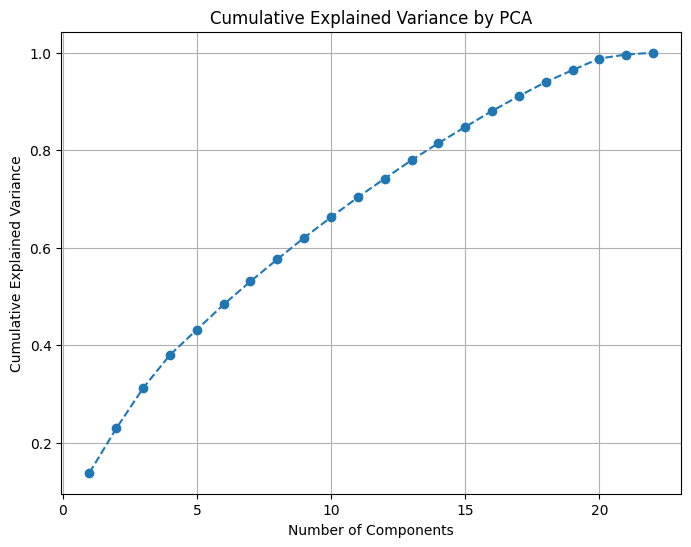

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.13722866 0.22968035 0.3118351  0.38133157 0.43350666 0.48529141
 0.53266311 0.57745541 0.62125326 0.66357468 0.70307207 0.74016734
 0.77655664 0.81200525 0.84549573 0.87764825 0.90722388 0.93608512
 0.96147912 0.98581509 0.99583398 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


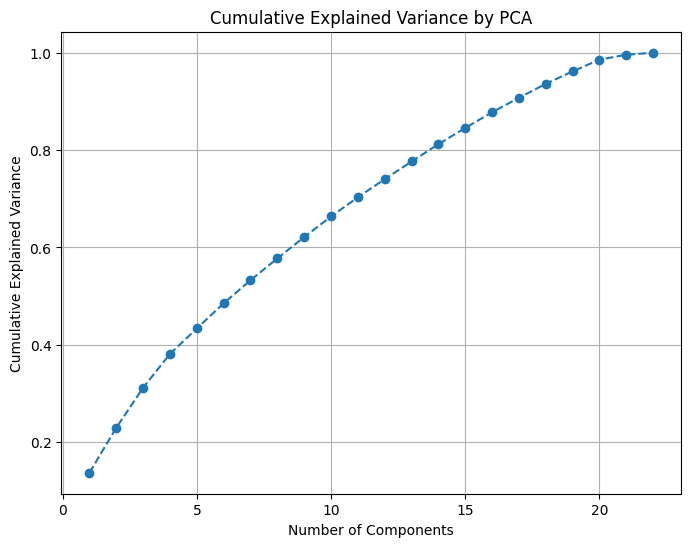

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.13626942 0.22950598 0.31207114 0.38243108 0.43513997 0.48624494
 0.53456426 0.58021754 0.62455663 0.66630036 0.70747667 0.74431146
 0.78076957 0.81582423 0.84932426 0.88203366 0.91112331 0.93973618
 0.96403642 0.98723557 0.99626485 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


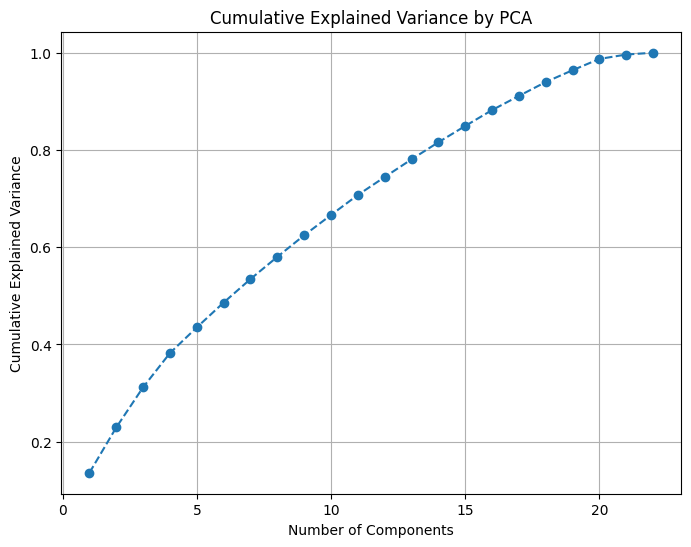

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.13702173 0.22808734 0.30756404 0.37600277 0.43003417 0.48261743
 0.53134626 0.57495133 0.61775664 0.65957438 0.69947393 0.73752809
 0.77491275 0.81151222 0.84470147 0.87706589 0.90759469 0.93680293
 0.96254837 0.98662635 0.99596972 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


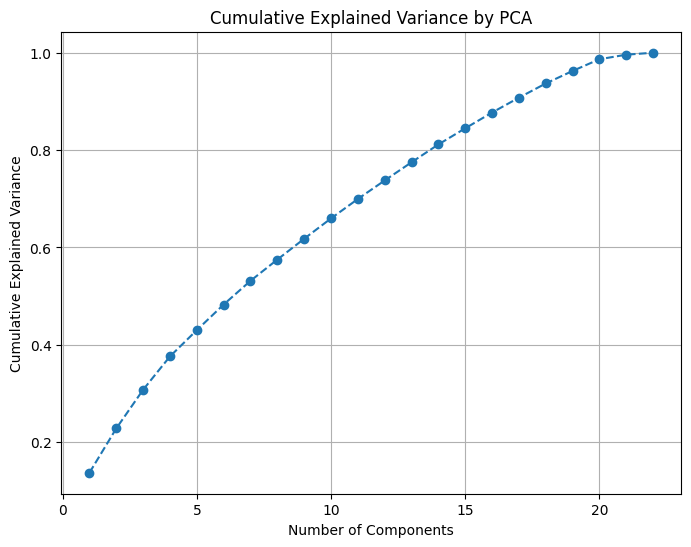

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.13511016 0.2261392  0.30952846 0.37827893 0.43068105 0.4814354
 0.52924674 0.5733052  0.61649822 0.65813718 0.69894368 0.73712313
 0.77496102 0.81188208 0.84595557 0.87873901 0.90899274 0.93808096
 0.9625418  0.98606111 0.99622081 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


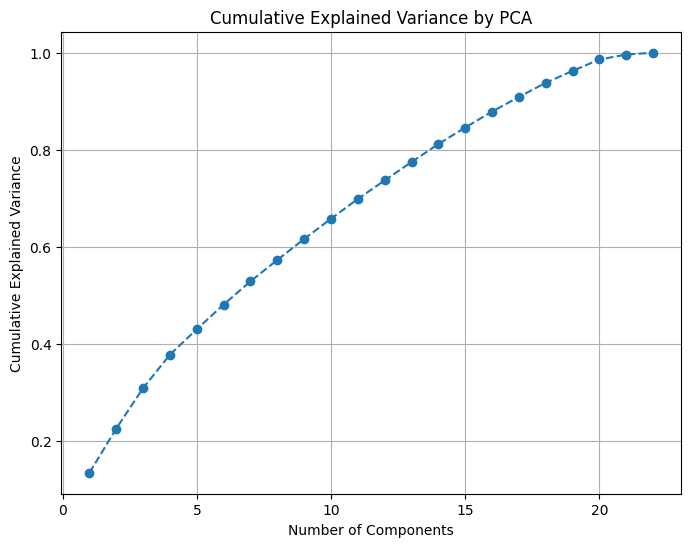

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Cumulative explained variance for each number of components: [0.1386622  0.23105018 0.31311137 0.3826848  0.43652709 0.4877686
 0.5365762  0.58218261 0.62518427 0.667042   0.7073102  0.74468304
 0.78029969 0.81475459 0.8472627  0.87931785 0.90908042 0.93783417
 0.96329812 0.98766977 0.99576804 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


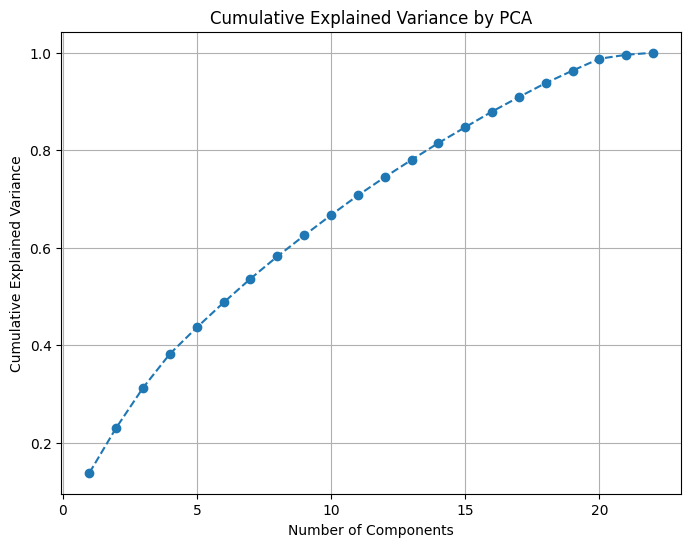

The optimal number of components to capture 85% of the variance is: 16


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


            Model  Accuracy  Precision    Recall  F1 Score
0   Decision Tree  0.519296   0.520784  0.519296  0.519979
1   Random Forest  0.638479   0.654961  0.638479  0.600560
2     Naïve Bayes  0.595914   0.490121  0.595914  0.503204
3             SVM  0.627128   0.574505  0.627128  0.578831
4   Decision Tree  0.497162   0.505574  0.497162  0.501026
5   Random Forest  0.620885   0.595244  0.620885  0.575109
6     Naïve Bayes  0.519864   0.428805  0.519864  0.432644
7             SVM  0.627696   0.582096  0.627696  0.581050
8   Decision Tree  0.518729   0.521009  0.518729  0.519852
9   Random Forest  0.626561   0.595662  0.626561  0.583103
10    Naïve Bayes  0.528944   0.437304  0.528944  0.443083
11            SVM  0.632804   0.586239  0.632804  0.588587
12  Decision Tree  0.502270   0.508950  0.502270  0.505086
13  Random Forest  0.622020   0.572721  0.622020  0.574612
14    Naïve Bayes  0.588536   0.500513  0.588536  0.494373
15            SVM  0.628831   0.584844  0.628831  0.5808

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_pca = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])
# Diccionario para almacenar los DataFrames procesados
pca_data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        scaler = StandardScaler()
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_test = scaler.transform(X_test_quantitative)

        # Aplicar PCA
        pca = PCA()
        pca.fit(X_scaled_train)

        # Obtener y mostrar la varianza acumulada
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = explained_variance.cumsum()
        print(f"Cumulative explained variance for each number of components: {cumulative_variance}")

        # Graficar la varianza acumulada
        plt.figure(figsize=(8, 6))
        plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
        plt.title('Cumulative Explained Variance by PCA')
        plt.xlabel('Number of Components')
        plt.ylabel('Cumulative Explained Variance')
        plt.grid(True)
        plt.show()

        # Determinar el número óptimo de componentes
        optimal_components = next(i for i, value in enumerate(cumulative_variance) if value >= 0.85) + 1
        print(f"The optimal number of components to capture 85% of the variance is: {optimal_components}")

        # Aplicar PCA con el número óptimo de componentes
        pca_optimal = PCA(n_components=optimal_components)
        X_pca_optimal_train = pca_optimal.fit_transform(X_scaled_train)
        X_pca_optimal_val = pca_optimal.transform(X_scaled_val)
        X_pca_optimal_test = pca_optimal.transform(X_scaled_test)

        # Crear DataFrames para las componentes principales
        original_X_train_index = X_train.index
        original_X_val_index = X_val.index
        original_X_test_index = X_test.index

        pca_X_train = pd.DataFrame(X_pca_optimal_train, index=original_X_train_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_train = pd.concat([pca_X_train, X_train_qualitative], axis=1)

        pca_X_val = pd.DataFrame(X_pca_optimal_val, index=original_X_val_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_val = pd.concat([pca_X_val, X_val_qualitative], axis=1)

        pca_X_test = pd.DataFrame(X_pca_optimal_test, index=original_X_test_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_test = pd.concat([pca_X_test, X_test_qualitative], axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': pca_X_train,
            'Train_Y': y_train,
            'Validation_X': pca_X_val,
            'Validation_Y': y_val,
            'Test_X': pca_X_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        pca_data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(pca_X_train, y_train)
        y_pred_dt = model_dt.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_dt,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_dt,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(pca_X_train, y_train)
        y_pred_rf = model_rf.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_rf,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_rf,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(pca_X_train, y_train)
        y_pred_nb = model_nb.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_nb,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_nb,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(pca_X_train, y_train)
        y_pred_svm = model_svm.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_svm,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_svm,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_pca)



#### 🛑 Results for predefinded Models

In [42]:
# Promedios por modelo
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.513736,0.517565,0.513736,0.515342
Naïve Bayes,0.521117,0.465050,0.521117,0.433337
Random Forest,0.633613,0.600420,0.633613,0.590731
SVM,0.633386,0.584604,0.633386,0.585844


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **Random Forest and SVM** models. These models demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.4 PCA Hyperparameter Turning

``````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_pca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_pca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_pca_SVM = pd.concat([df_hyperparameters_gridsearch_pca_SVM, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_pca_SVM = pd.concat([df_hyperparameters_randomsearch_pca_SVM, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch_pca_SVM)
df_hyperparameters_gridsearch_pca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_PCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch_pca_SVM)
df_hyperparameters_randomsearch_pca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_PCA_SVM.csv')


In [43]:
df_hyperparameters_gridsearch_pca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_PCA_SVM.csv')
df_hyperparameters_randomsearch_pca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_PCA_SVM.csv')

#### SVM 1.4 PCA Hyperparameter Turning

```````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_PCA_RF = pd.DataFrame(columns=['Fold','criterion', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])
df_hyperparameters_randomsearch_PCA_RF = pd.DataFrame(columns=['Fold','criterion','n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])

# Modelo base
model_rf = RandomForestClassifier(random_state=42)

# Espacio de hiperparámetros para GridSearchCV
param_grid_rf = {
    'n_estimators': [10, 20],  # Número de árboles
    'max_depth': [None, 10, 20],  # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Número de características a considerar para dividir
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(10, 20),  # Número aleatorio de árboles
    'max_depth': [None] + list(range(10, 101, 10)),  # Profundidad aleatoria
    'min_samples_split': randint(2, 20),  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': randint(1, 10),  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Características a considerar
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_rf,
            param_grid=param_grid_rf,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': grid_search.best_params_['criterion'],
            'n_estimators': grid_search.best_params_['n_estimators'],
            'max_depth': grid_search.best_params_['max_depth'],
            'min_samples_split': grid_search.best_params_['min_samples_split'],
            'min_samples_leaf': grid_search.best_params_['min_samples_leaf'],
            'max_features': grid_search.best_params_['max_features'],
            'bootstrap': grid_search.best_params_['bootstrap'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_PCA_RF = pd.concat([df_hyperparameters_gridsearch_PCA_RF, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_rf,
            param_distributions=param_dist_rf,
            n_iter=10,
            scoring='accuracy',
            cv=5,
            random_state=42
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': random_search.best_params_['criterion'],
            'n_estimators': random_search.best_params_['n_estimators'],
            'max_depth': random_search.best_params_['max_depth'],
            'min_samples_split': random_search.best_params_['min_samples_split'],
            'min_samples_leaf': random_search.best_params_['min_samples_leaf'],
            'max_features': random_search.best_params_['max_features'],
            'bootstrap': random_search.best_params_['bootstrap'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_PCA_RF = pd.concat([df_hyperparameters_randomsearch_PCA_RF, new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_PCA_RF)
df_hyperparameters_gridsearch_PCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_PCA_RF.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_PCA_RF)
df_hyperparameters_randomsearch_PCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_PCA_RF.csv')


In [44]:
df_hyperparameters_gridsearch_PCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_PCA_RF.csv')
df_hyperparameters_randomsearch_PCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_PCA_RF.csv')

### 🟢 Evaluation of SVM and Random Forest Models for SFDM2 Prediction with PCA (Hyperparameter Tuning)

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH SVM**

In [45]:
df_hyperparameter_turning = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'rbf')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        recall_GS = recall_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        f1_GS = f1_score(data['Test_Y'], y_pred_GS,average = 'weighted')

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS]
        })
        df_hyperparameter_turning=pd.concat([df_hyperparameter_turning,new_row], ignore_index=True)

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_4661/2387819812.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_hyperparameter_turning=pd.concat([df_hyperparameter_turning,new_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-d

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH SVM**

In [46]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=1.047654030943257,
            degree=5,
            gamma='auto',
            kernel='rbf'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average = 'weighted')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average = 'weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average = 'weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning = pd.concat([df_hyperparameter_turning, new_row], ignore_index=True)



/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH RF**

In [47]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=20,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features='sqrt',
            max_depth=10,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='weighted')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='weighted')        
        f1_GS = f1_score(data['Test_Y'], y_pred_GS, average='weighted')                
       

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning = pd.concat([df_hyperparameter_turning, new_row], ignore_index=True)

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH RF**

In [48]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=16,
            min_samples_split=10,
            min_samples_leaf=2,
            max_features='sqrt',
            max_depth=90,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='weighted')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning = pd.concat([df_hyperparameter_turning, new_row], ignore_index=True)

df_hyperparameter_turning.groupby('Model').mean()

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

,Accuracy,Precision,Recall,F1 Score
Model,,,,
RANDOM FOREST GS,0.631854,0.584476,0.631854,0.585790
RANDOM FOREST RS,0.627369,0.586118,0.627369,0.588585
Super Vector Machine GS,0.633386,0.584604,0.633386,0.585844
Support Vector Machine RS,0.633499,0.581358,0.633499,0.588772


## 🛑 Task 1.4. WITHOUT PCA:  **Prediction of SFDM2**

---



### 🛑 DATA SPLICING

- First, we separate the data into the target variable and the features.

In [49]:
target=df['sfdm2']
features=df.drop(['sfdm2'],axis=1)
categorical_features_cols= categorical_features.drop(['sfdm2'],axis=1).columns

In [50]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_scaled= pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])
# Diccionario para almacenar los DataFrames procesados
data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(X_scaled_train, y_train)
        y_pred_dt = model_dt.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_dt,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_dt,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(X_scaled_train, y_train)
        y_pred_rf = model_rf.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_rf,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_rf,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(X_scaled_train, y_train)
        y_pred_nb = model_nb.predict(X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_nb,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_nb,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(X_scaled_train, y_train)
        y_pred_svm = model_svm.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_svm,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_svm,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_scaled)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_4661/2163508823.py:83: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is 

            Model  Accuracy  Precision    Recall  F1 Score
0   Decision Tree  0.547673   0.556248  0.547673  0.551395
1   Random Forest  0.652100   0.639717  0.652100  0.613690
2     Naïve Bayes  0.582293   0.644718  0.582293  0.503574
3             SVM  0.637344   0.588376  0.637344  0.593225
4   Decision Tree  0.531782   0.540597  0.531782  0.535814
5   Random Forest  0.653802   0.610679  0.653802  0.615880
6     Naïve Bayes  0.569240   0.536268  0.569240  0.504617
7             SVM  0.631101   0.584319  0.631101  0.586138
8   Decision Tree  0.540295   0.534750  0.540295  0.537046
9   Random Forest  0.643587   0.610347  0.643587  0.604614
10    Naïve Bayes  0.552781   0.521479  0.552781  0.483711
11            SVM  0.640182   0.595496  0.640182  0.597922
12  Decision Tree  0.526674   0.526354  0.526674  0.526489
13  Random Forest  0.653235   0.618470  0.653235  0.614447
14    Naïve Bayes  0.587968   0.503502  0.587968  0.510150
15            SVM  0.637344   0.597934  0.637344  0.5940

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### 🛑 Results for predefinded Models

In [51]:
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.546999,0.549658,0.546999,0.547959
Naïve Bayes,0.549326,0.544114,0.549326,0.483017
Random Forest,0.660007,0.627111,0.660007,0.621689
SVM,0.640197,0.594370,0.640197,0.595625


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **Random Forest and SVM** models. These models demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.3 No PCA Hyperparameter Turning

````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_Nopca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_Nopca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_Nopca_SVM = pd.concat([df_hyperparameters_gridsearch_Nopca_SVM, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_Nopca_SVM = pd.concat([df_hyperparameters_randomsearch_Nopca_SVM, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch_Nopca_SVM)
df_hyperparameters_gridsearch_Nopca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_NoPCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch_Nopca_SVM)
df_hyperparameters_randomsearch_Nopca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_NoPCA_SVM.csv')

In [52]:
df_hyperparameters_gridsearch_NoPCA_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_NoPCA_SVM.csv')
df_hyperparameters_randomsearch_NoPCA_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_NoPCA_SVM.csv')
df_hyperparameters_gridsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_NoPCA_RF.csv')
df_hyperparameters_randomsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_NoPCA_RF.csv')

In [53]:
df_hyperparameters_gridsearch_NoPCA_RF[df_hyperparameters_gridsearch_NoPCA_SVM['Accuracy'] == df_hyperparameters_gridsearch_NoPCA_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
3,3,Fold_Externo_1-Fold_Interno_2,entropy,20,NaN,10,2,sqrt,True,0.659943


In [54]:
df_hyperparameters_randomsearch_NoPCA_SVM[df_hyperparameters_randomsearch_NoPCA_SVM['Accuracy'] == df_hyperparameters_randomsearch_NoPCA_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
9,9,Fold_Externo_4-Fold_Interno_2,68.762028,linear,3,auto,0.633363


#### RandomForest 1.3 NO PCA Hyperparameter Turning

`````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_NoPCA_RF = pd.DataFrame(columns=['Fold','criterion', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])
df_hyperparameters_randomsearch_NoPCA_RF = pd.DataFrame(columns=['Fold','criterion','n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])

# Modelo base
model_rf = RandomForestClassifier(random_state=42)

# Espacio de hiperparámetros para GridSearchCV
param_grid_rf = {
    'n_estimators': [10, 20],  # Número de árboles
    'max_depth': [None, 10, 20],  # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Número de características a considerar para dividir
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(10, 20),  # Número aleatorio de árboles
    'max_depth': [None] + list(range(10, 101, 10)),  # Profundidad aleatoria
    'min_samples_split': randint(2, 20),  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': randint(1, 10),  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Características a considerar
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_rf,
            param_grid=param_grid_rf,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': grid_search.best_params_['criterion'],
            'n_estimators': grid_search.best_params_['n_estimators'],
            'max_depth': grid_search.best_params_['max_depth'],
            'min_samples_split': grid_search.best_params_['min_samples_split'],
            'min_samples_leaf': grid_search.best_params_['min_samples_leaf'],
            'max_features': grid_search.best_params_['max_features'],
            'bootstrap': grid_search.best_params_['bootstrap'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_NoPCA_RF = pd.concat([df_hyperparameters_gridsearch_NoPCA_RF, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_rf,
            param_distributions=param_dist_rf,
            n_iter=10,
            scoring='accuracy',
            cv=5,
            random_state=42
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': random_search.best_params_['criterion'],
            'n_estimators': random_search.best_params_['n_estimators'],
            'max_depth': random_search.best_params_['max_depth'],
            'min_samples_split': random_search.best_params_['min_samples_split'],
            'min_samples_leaf': random_search.best_params_['min_samples_leaf'],
            'max_features': random_search.best_params_['max_features'],
            'bootstrap': random_search.best_params_['bootstrap'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_NoPCA_RF = pd.concat([df_hyperparameters_randomsearch_NoPCA_RF, new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_NoPCA_RF)
df_hyperparameters_gridsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_NoPCA_RF.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_NoPCA_RF)
df_hyperparameters_randomsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_NoPCA_RF.csv')


In [55]:
df_hyperparameters_gridsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/GRIDSEARCH_NoPCA_RF.csv')
df_hyperparameters_randomsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.4_Model Analysis For  SFDM2/RANDOMSEARCH_NoPCA_RF.csv')

In [56]:
df_hyperparameters_gridsearch_NoPCA_RF[df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'] == df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
1,1,Fold_Externo_0-Fold_Interno_2,entropy,20,10.0,10,4,sqrt,False,0.663633


In [57]:
df_hyperparameters_randomsearch_NoPCA_RF[df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'] == df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
3,3,Fold_Externo_1-Fold_Interno_2,gini,15,50,13,2,sqrt,False,0.65739


### 🟢 Evaluation of SVM and Random Forest Models for SFDM2 Prediction with NoPCA (Hyperparameter Tuning)

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH SVM**

In [58]:
df_hyperparameter_turning_NoPCA = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'rbf')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        recall_GS = recall_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        f1_GS = f1_score(data['Test_Y'], y_pred_GS,average = 'weighted')

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS]
        })
        df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_4661/1627377237.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precis

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH SVM**

In [59]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=68.7620275249795,
            degree=3,
            gamma='auto',
            kernel='linear'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average = 'weighted')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average = 'weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average = 'weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)



/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH RF**

In [60]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=10,
            min_samples_split=15,
            min_samples_leaf=3,
            max_features='sqrt',
            max_depth=70,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='weighted')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='weighted')        
        f1_GS = f1_score(data['Test_Y'], y_pred_GS, average='weighted')                
       

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH RF**

In [61]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=20,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features='sqrt',
            max_depth=10,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='weighted')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,

        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA  = pd.concat([df_hyperparameter_turning_NoPCA , new_row], ignore_index=True)

df_hyperparameter_turning_NoPCA.groupby('Model').mean()

/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

,Accuracy,Precision,Recall,F1 Score
Model,,,,
RANDOM FOREST GS,0.621580,0.581134,0.621580,0.581747
RANDOM FOREST RS,0.631854,0.584476,0.631854,0.585790
Super Vector Machine GS,0.633386,0.584604,0.633386,0.585844
Support Vector Machine RS,0.616415,0.562311,0.616415,0.564631


# 🟢 Results Tasks 1.4

### **ANALYSIS: Models obtained with data trained using PCA**

In [62]:
# Promedios por modelo by default con PCA
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.513736,0.517565,0.513736,0.515342
Naïve Bayes,0.521117,0.465050,0.521117,0.433337
Random Forest,0.633613,0.600420,0.633613,0.590731
SVM,0.633386,0.584604,0.633386,0.585844


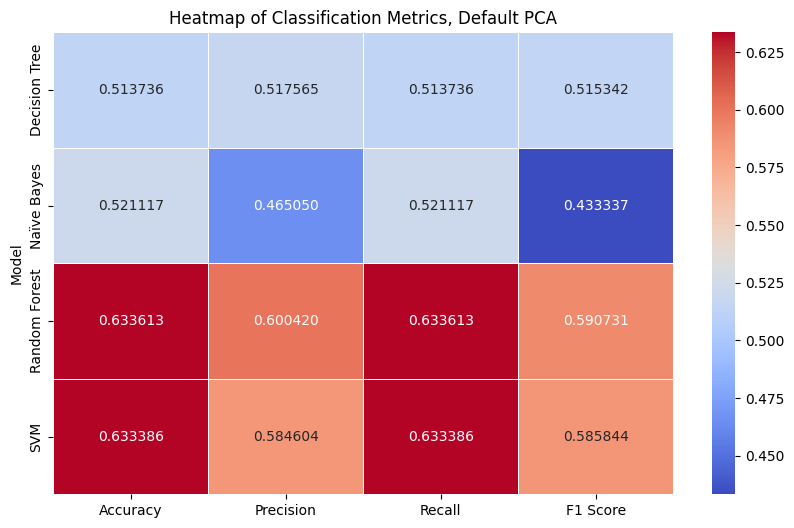

In [63]:
df_heatmap = evaluation_metrics_pca.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default PCA")
plt.show()

As we can observe on the heatmap of model obtained with the trained data using PCA, we have made the study of both the SVM and Random Forest models. We have selected these ones because they show the highest values in most metrics being effective for the classification task.

In [64]:
df_hyperparameter_turning.groupby('Model').mean()


,Accuracy,Precision,Recall,F1 Score
Model,,,,
RANDOM FOREST GS,0.631854,0.584476,0.631854,0.585790
RANDOM FOREST RS,0.627369,0.586118,0.627369,0.588585
Super Vector Machine GS,0.633386,0.584604,0.633386,0.585844
Support Vector Machine RS,0.633499,0.581358,0.633499,0.588772


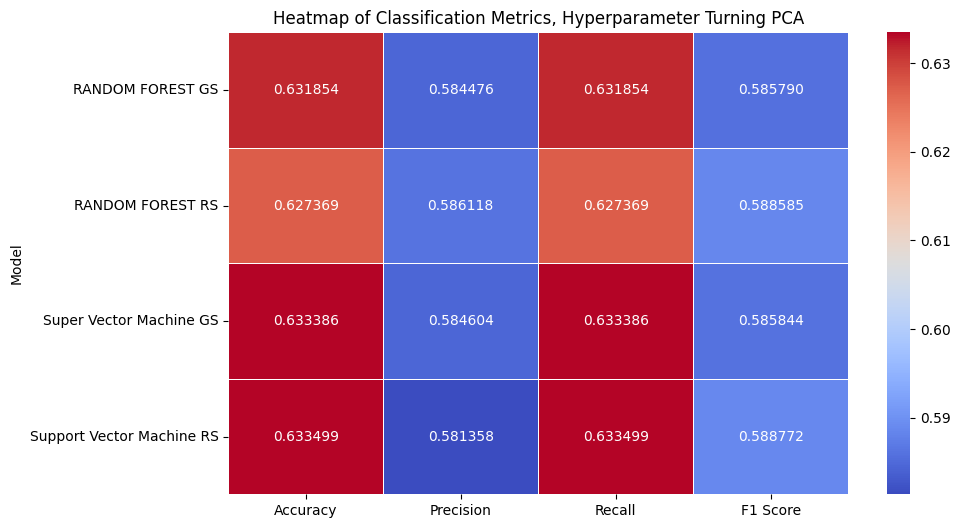

In [65]:
df_heatmap = df_hyperparameter_turning.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning PCA")
plt.show()

Looking at the heatmap above, we can visualize all the values of the metrics clearly. The Support Vector Machine RS model does the best performance in all key metrics, achieving the highest “Accuracy”, “Recall”, and “F1 Score”, along with strong “Precision”, making it the most reliable model for this dataset. Nevertheless, the Random Forest GS and Super Vector Machine GS models are also strong contenders with high “Recall” and “F1 Score” and Random Forest RS model performs slightly worse across all metrics, particularly in “Recall” and “F1 Score”. 


### **ANALYSIS: Models obtained with data trained without using PCA**

In [66]:
# Promedios por modelo by default sin PCA, valores escalados
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.546999,0.549658,0.546999,0.547959
Naïve Bayes,0.549326,0.544114,0.549326,0.483017
Random Forest,0.660007,0.627111,0.660007,0.621689
SVM,0.640197,0.594370,0.640197,0.595625


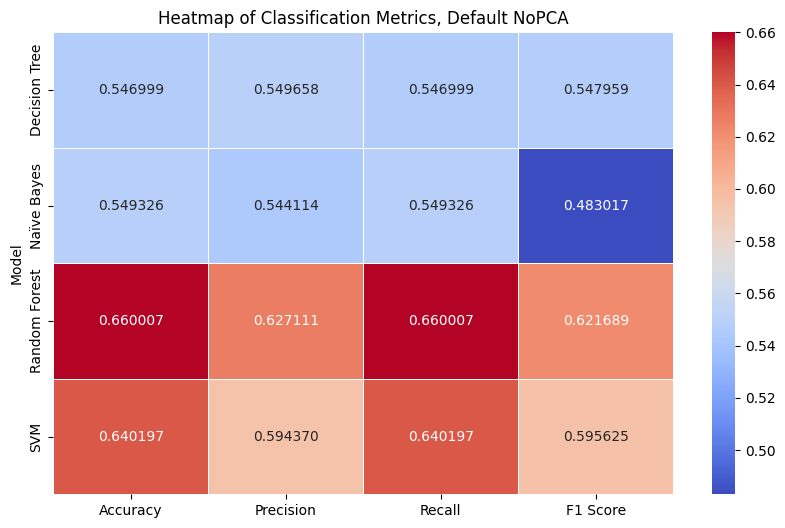

In [67]:
df_heatmap = evaluation_metrics_scaled.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default NoPCA")
plt.show()

The Random Forest model stands out as the best, obtaining the highest values ​​in all metrics: Precision, Accuracy, Recall and F1 Score, with a maximum of **0.66** in Accuracy and Recall. SVM follows in performance, with solid values ​​in Recall and Accuracy (**0.64**), although its Precision and F1 Score are lower. Naive Bayes shows consistent results in three metrics (**0.54**), but its F1 Score is the lowest (**0.48**). Finally, the Decision Tree presents uniform metrics (**0.547**), but lower than the Random Forest and SVM. Random Forest is the most robust model, significantly outperforming the rest.

In [68]:
df_hyperparameter_turning_NoPCA.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
RANDOM FOREST GS,0.621580,0.581134,0.621580,0.581747
RANDOM FOREST RS,0.631854,0.584476,0.631854,0.585790
Super Vector Machine GS,0.633386,0.584604,0.633386,0.585844
Support Vector Machine RS,0.616415,0.562311,0.616415,0.564631


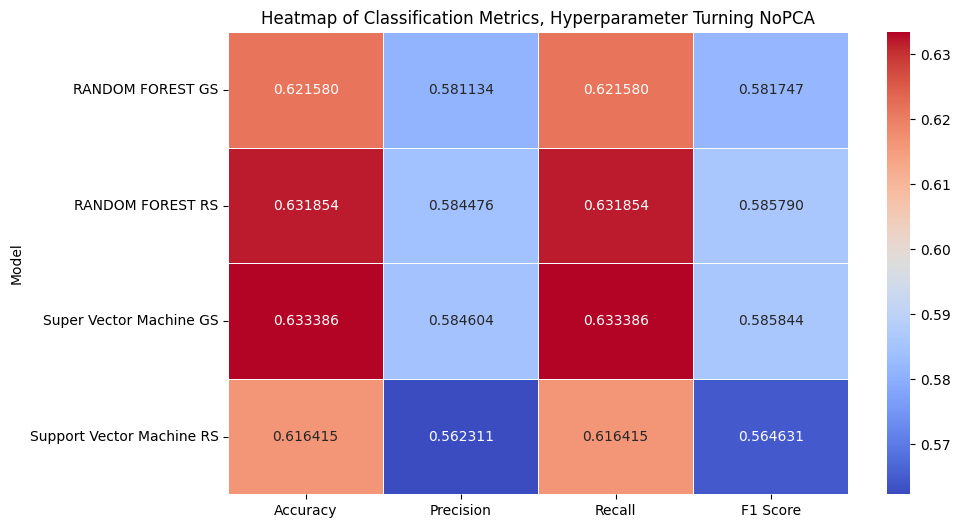

In [69]:
df_heatmap = df_hyperparameter_turning_NoPCA.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning NoPCA")
plt.show()

Comparing the two graphs, it can be seen that the **Random Forest Default** model in the first graph outperforms the hyperparameter-tuned models (second graph) in terms of **Accuracy** and other key metrics. This model achieves an **Accuracy of 0.66**, along with a **Recall of 0.66** and an **F1 Score of 0.621689**, standing out as the most effective overall.

In the second graph, the hyperparameter-tuned models (Random Search and Grid Search) show minor improvements in some individual metrics, but do not reach the performance level of the Random Forest Default. For example, the **Random Forest RS** model achieves an Accuracy of **0.631854**, lower than the default model. This suggests that in this case the **Random Forest Default** offers the best balance between simplicity and performance, making hyperparameter tuning unnecessary to significantly improve its metrics.

### **ANALYSIS: Better PCA Model vs No PCA Model**

When comparing the two best models, PCA and NoPCA, it can be observed that in the scenario with PCA and hyperparameter tuning (first graph), the best models achieve accuracies close to 63% and F1 close to 0.59 (for example, Support Vector Machine with Random Search). However, in the second graph, without PCA and with default parameters, it is evident that the Random Forest exceeds this mark, reaching an accuracy of approximately 66% and an F1 of around 0.62. This suggests that, when comparing the entire set of results, the Random Forest model without PCA and with default parameters achieves the strongest overall performance.